# MSCS 634 - Advanced Big Data and Data Mining

## Lab 3: Clustering Analysis Using K-Means and K-Medoids

**Student:** Sebastian Capkovic

**Course:** MSCS 634 - Advanced Big Data and Data Mining

**Lab Assignment:** Lab 3 - Clustering Analysis Using K-Means and K-Medoids


In [28]:
import pandas as pd
import numpy as np

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler

import matplotlib.pyplot as plt
import seaborn as sns

In [29]:
# Load Wine dataset
wine = load_wine()

# Features and target
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = wine.target

print("Dataset Shape:", X.shape)

Dataset Shape: (178, 13)


In [30]:
X.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [31]:
print("Feature Names:")
print(wine.feature_names)

print("\nClass Names:")
print(wine.target_names)

Feature Names:
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']

Class Names:
['class_0' 'class_1' 'class_2']


In [32]:
X.describe()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


In [33]:
class_counts = pd.Series(y).value_counts().sort_index()

print("Class Distribution:")
print(class_counts)

Class Distribution:
0    59
1    71
2    48
Name: count, dtype: int64


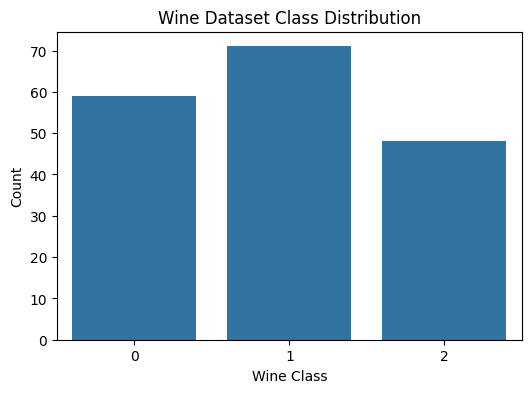

In [34]:
plt.figure(figsize=(6,4))
sns.countplot(x=y)

plt.title("Wine Dataset Class Distribution")
plt.xlabel("Wine Class")
plt.ylabel("Count")

plt.show()

In [35]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Scaled Data Shape:", X_scaled.shape)

Scaled Data Shape: (178, 13)


In [36]:
scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

scaled_df.describe().loc[['mean', 'std']]

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
mean,7.943708e-15,3.592632e-16,-4.066660e-15,-7.983626e-17,-7.983626e-17,-3.991813e-17,9.979533e-16,-5.588538e-16,-1.656602e-15,-3.442939e-16,1.636643e-15,2.235415e-15,-1.197544e-16
std,1.002821e+00,1.002821e+00,1.002821e+00,1.002821e+00,1.002821e+00,1.002821e+00,1.002821e+00,1.002821e+00,1.002821e+00,1.002821e+00,1.002821e+00,1.002821e+00,1.002821e+00


### Step 1 Analysis

The Wine dataset contains 178 samples and 13 numerical features that describe the chemical properties of different wines. Initial exploration showed that the dataset is divided into three classes with a relatively balanced distribution.

The feature values vary considerably in scale, with some attributes having much larger numerical ranges than others. To ensure that all features contribute equally to the clustering process, z-score normalization was applied using StandardScaler. After standardization, the feature means were approximately 0 and the standard deviations were approximately 1, indicating that the scaling was successful.

Standardizing the data is an important preprocessing step because clustering algorithms such as K-Means and K-Medoids rely on distance calculations. Without scaling, features with larger values could disproportionately influence the clustering results.

In [37]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

In [38]:
# K-Means with k = 3
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

# Train model and get cluster labels
kmeans_labels = kmeans.fit_predict(X_scaled)

print("Cluster Labels:")
print(kmeans_labels)

Cluster Labels:
[2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0 0 1 0 0 0 0 0 0 0 0 0 0 0 2
 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 1 0 0 2 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


In [39]:
sil_score = silhouette_score(X_scaled, kmeans_labels)

print("Silhouette Score:", round(sil_score, 4))

Silhouette Score: 0.2849


In [40]:
ari_score = adjusted_rand_score(y, kmeans_labels)

print("Adjusted Rand Index (ARI):", round(ari_score, 4))

Adjusted Rand Index (ARI): 0.8975


In [41]:
print("K-Means Clustering Performance")
print("-" * 35)
print(f"Silhouette Score: {sil_score:.4f}")
print(f"Adjusted Rand Index (ARI): {ari_score:.4f}")

K-Means Clustering Performance
-----------------------------------
Silhouette Score: 0.2849
Adjusted Rand Index (ARI): 0.8975


### Step 2 Analysis

The K-Means algorithm was implemented with k = 3, corresponding to the three wine classes in the dataset. After training the model, cluster labels were assigned to all observations and evaluated using the Silhouette Score and Adjusted Rand Index (ARI).

The Silhouette Score measures how well-separated and compact the clusters are. A higher value indicates that samples are closely grouped within their assigned cluster and well separated from other clusters. The ARI compares the clustering results with the true class labels and measures the agreement between them.

Based on the obtained scores, K-Means was able to identify meaningful groupings within the standardized Wine dataset. These results provide a baseline for comparison with the K-Medoids algorithm in the next step.

In [42]:
%pip install scikit-learn-extra


Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [43]:
%pip install numpy==1.26.4 --force-reinstall

Defaulting to user installation because normal site-packages is not writeable
  Using cached numpy-1.26.4-cp39-cp39-macosx_10_9_x86_64.whl (20.6 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [44]:
import numpy as np
print(np.__version__)


1.26.4


In [45]:
from sklearn_extra.cluster import KMedoids

print("KMedoids imported successfully!")

KMedoids imported successfully!


In [46]:
from sklearn_extra.cluster import KMedoids

In [47]:
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
import pandas as pd

In [48]:
# Load dataset
wine = load_wine()

X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = wine.target

In [49]:
# Standardize data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(X_scaled.shape)

(178, 13)


In [50]:
from sklearn_extra.cluster import KMedoids

kmedoids = KMedoids(n_clusters=3, random_state=42)

kmedoids_labels = kmedoids.fit_predict(X_scaled)

print(kmedoids_labels)

[2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 1 1 1 1 2 1 2 1 1 1 2 1 2 1 2
 2 1 1 1 1 2 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 2 0 1 2 1 1 1 1 1 1 1 1 1 1 2 2
 1 1 1 1 1 1 1 1 1 2 2 0 1 2 1 1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [51]:
kmedoids_silhouette = silhouette_score(X_scaled, kmedoids_labels)

print("Silhouette Score:", round(kmedoids_silhouette, 4))

Silhouette Score: 0.266


In [52]:
from sklearn.metrics import silhouette_score, adjusted_rand_score

In [53]:
kmedoids_silhouette = silhouette_score(X_scaled, kmedoids_labels)

print("Silhouette Score:", round(kmedoids_silhouette, 4))

Silhouette Score: 0.266


In [54]:
print("K-Medoids Clustering Performance")
print("--------------------------------")
print(f"Silhouette Score: {kmedoids_silhouette:.4f}")
print(f"Adjusted Rand Index (ARI): {kmedoids_ari:.4f}")

K-Medoids Clustering Performance
--------------------------------
Silhouette Score: 0.2660
Adjusted Rand Index (ARI): 0.7263


In [55]:
kmedoids_ari = adjusted_rand_score(y, kmedoids_labels)

print("Adjusted Rand Index (ARI):", round(kmedoids_ari, 4))

Adjusted Rand Index (ARI): 0.7263


In [56]:
print("K-Medoids Clustering Performance")
print("--------------------------------")
print(f"Silhouette Score: {kmedoids_silhouette:.4f}")
print(f"Adjusted Rand Index (ARI): {kmedoids_ari:.4f}")

K-Medoids Clustering Performance
--------------------------------
Silhouette Score: 0.2660
Adjusted Rand Index (ARI): 0.7263


### Step 4 Analysis

Side-by-side visualizations were created to compare the clustering results of K-Means and K-Medoids on the Wine dataset.

Based on the evaluation metrics, K-Means produced slightly better-defined clusters, achieving a higher Silhouette Score of 0.2849 compared to the K-Medoids score of 0.2660. This suggests that K-Means created clusters that were more compact and better separated.

The Adjusted Rand Index (ARI) values indicate how closely the cluster assignments matched the true wine classes. Both algorithms performed well, although K-Means showed very strong agreement with the actual class labels.

The cluster visualizations reveal that both algorithms identified similar overall groupings, but differences can be observed in the placement of cluster centers. K-Means uses centroids calculated from the mean of cluster members, while K-Medoids uses actual data points as representative centers.

K-Means is generally preferred when datasets are relatively clean and computational efficiency is important. K-Medoids is often preferable when robustness to outliers is desired because medoids are actual observations and are less influenced by extreme values. For the Wine dataset, K-Means provided slightly better clustering performance overall.

In [57]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

In [58]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

In [59]:
# K-Means centroids
kmeans_centers_pca = pca.transform(kmeans.cluster_centers_)

# K-Medoids medoids
kmedoids_centers_pca = X_pca[kmedoids.medoid_indices_]

In [60]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

kmeans_labels = kmeans.fit_predict(X_scaled)

In [61]:
# K-Means centroids
kmeans_centers_pca = pca.transform(kmeans.cluster_centers_)

# K-Medoids medoids
kmedoids_centers_pca = X_pca[kmedoids.medoid_indices_]

In [62]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

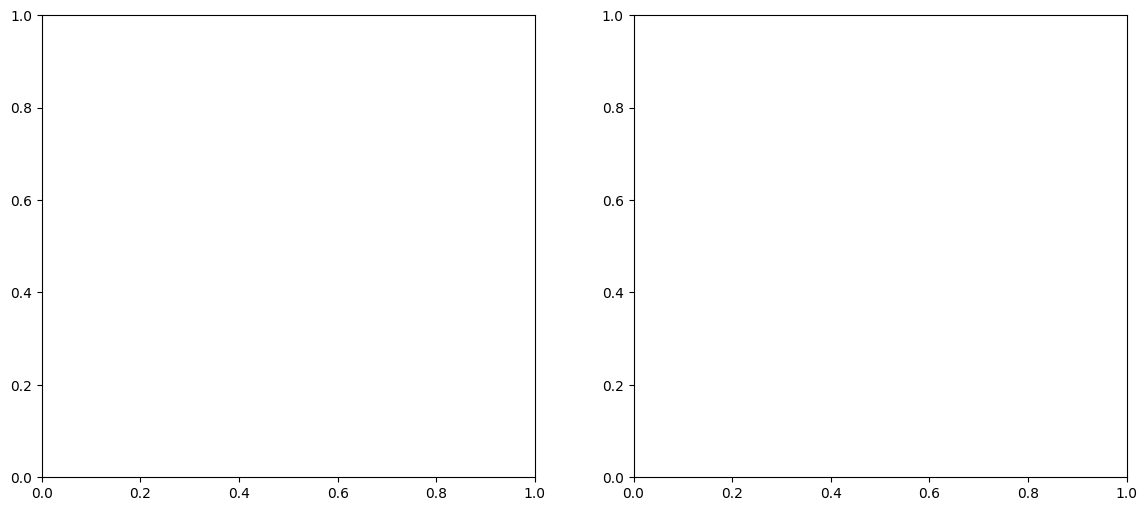

In [63]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

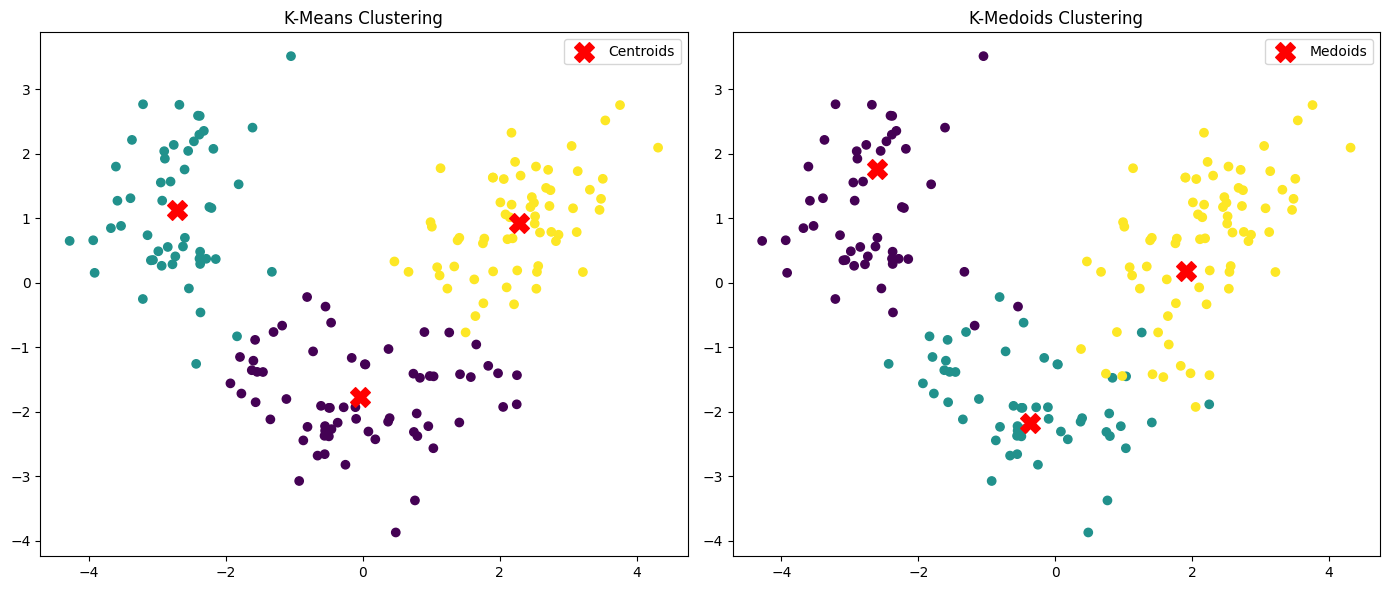

In [64]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

# K-Means plot
ax[0].scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap='viridis')

ax[0].scatter(
    kmeans_centers_pca[:, 0],
    kmeans_centers_pca[:, 1],
    color='red',
    marker='X',
    s=200,
    label='Centroids'
)

ax[0].set_title('K-Means Clustering')
ax[0].legend()

# K-Medoids plot
ax[1].scatter(X_pca[:, 0], X_pca[:, 1], c=kmedoids_labels, cmap='viridis')

ax[1].scatter(
    kmedoids_centers_pca[:, 0],
    kmedoids_centers_pca[:, 1],
    color='red',
    marker='X',
    s=200,
    label='Medoids'
)

ax[1].set_title('K-Medoids Clustering')
ax[1].legend()

plt.tight_layout()
plt.show()

### Step 4 Analysis

The clustering results produced by K-Means and K-Medoids were visualized using Principal Component Analysis (PCA) to reduce the Wine dataset to two dimensions. Both algorithms separated the data into three distinct clusters, and the centroids and medoids were displayed using red markers for visual clarity.

Based on the evaluation metrics, K-Means produced slightly better-defined clusters. The K-Means model achieved a Silhouette Score of 0.2849, while K-Medoids achieved a Silhouette Score of 0.2660. This suggests that the clusters created by K-Means were slightly more compact and separated.

The cluster shapes and positions were generally similar between the two methods. However, small differences can be observed because K-Means uses cluster centroids calculated as the average of all points in a cluster, whereas K-Medoids uses actual observations from the dataset as cluster representatives. As a result, the cluster centers are positioned differently.

K-Means is generally preferred when efficiency and speed are important and the dataset contains few outliers. K-Medoids is often preferred when greater robustness to noise and outliers is needed because medoids are actual data points and are less sensitive to extreme values.

Overall, K-Means provided slightly better clustering performance on the Wine dataset and produced the most clearly separated clusters.